# ME 203 — Test 2: Plotting and fitting experimental data

**Programming component: 4 tasks, 12 points**

Name: **[Tega Ikoba]**

Use the small dataset below to finish an analysis of a spring test. The techniques come from Lecture Activities 3–4, Labs 3–4, and Homework 1. Only NumPy, SciPy, and Matplotlib are needed. There are no external data files or Otter checks.

- Follow the permitted-resource rules posted with the test in Canvas.
- Keep the given variable and function names; edit the task cells and responses.
- Calculate answers from the data. Functions must work with other valid inputs in the documented format.
- Written answers should be one or two sentences referring to your results.
- Budget time to restart, run all cells, save, and upload the `.ipynb` file **before the test timer ends**. Keep the plot and printed outputs in your submission.
- If stuck, submit your attempted code for partial credit. The Inspect cells display results; they are not autograder checks.

The setup and fallback values allow later tasks to be attempted even if you cannot finish an earlier task. A fallback is not a solution to that earlier task.

## Setup — run without changing

Each row is **[displacement in mm, force in N, valid-reading flag]**. The flag is `1` for a valid reading and `0` for a reading known to have a sensor fault. The fault was recorded during collection; do not choose exclusions based on whether points fit the line.

Fit **force as a function of displacement** using only valid readings. The metadata gives the column positions.

In [1]:
import numpy as np
from scipy.stats import linregress
import matplotlib.pyplot as plt

spring_data = np.array([
    [0.0,  1.0, 1.0],
    [1.0,  3.0, 1.0],
    [2.0,  5.0, 1.0],
    [3.0, 40.0, 0.0],
    [4.0,  9.0, 1.0],
    [5.0, 11.0, 1.0],
    [6.0, 13.0, 1.0],
])
columns = {"displacement": 0, "force": 1, "valid": 2}


## Task 1 — Repair the data selection (2 points)

Repair this function so that it keeps only rows whose valid-reading flag equals `1`, then returns **displacement first, force second** as two one-dimensional arrays. Use the supplied data and column dictionary rather than global variables or literal column positions.

In [2]:
def get_valid_xy(data, column_info):
    # TODO: select valid rows and correct the returned column order.
    valid_data = data[:, 2] == 1
    selected = data[valid_data]
    xs = selected[:, column_info["force"]]
    ys = selected[:, column_info["displacement"]]
    return xs, ys

# DO NOT CHANGE CODE BELOW THIS
valid_x, valid_y = get_valid_xy(spring_data, columns)
print("Selected displacement:", valid_x)
print("Selected force:", valid_y)


Selected displacement: [ 1.  3.  5.  9. 11. 13.]
Selected force: [0. 1. 2. 4. 5. 6.]


## Task 2 — Complete the fitting function (3 points)

Call `linregress` with the supplied `xs` and `ys`, then return a dictionary with keys `"slope"` and `"intercept"` using the corresponding attributes of the regression result. Assume at least two paired points with distinct x values. Do not use global data inside the function.

In [3]:
def fit_line(xs, ys):
    # TODO: perform the regression and return the required dictionary.
    lr_data = linregress(xs, ys)
    lr_slope = lr_data.slope
    lr_intercept = lr_data.intercept
    return {"slope": lr_slope, "intercept": lr_intercept}  # Placeholder, not a solution.

# DO NOT CHANGE CODE BELOW THIS
fit_result = fit_line(valid_x, valid_y)
print("Fitted line:", fit_result)


Fitted line: {'slope': np.float64(0.5), 'intercept': np.float64(-0.5)}


## Task 3 — Repair and label the plot (4 points)

The scaffold already creates one set of axes and supplies arrays for plotting. Repair the two plot calls to show:

- `plot_y` versus `plot_x` as **unconnected blue circle markers**, labeled `"Valid measurements"`.
- `line_y` versus `line_x` as a **red solid line**, labeled `"Linear fit"`.

Add the x label `"Displacement (mm)"`, y label `"Force (N)"`, title `"Spring test"`, and a legend. Use `ax` methods and keep both datasets on these same axes.

By default this uses your earlier answers. If an earlier task prevents a meaningful plot, set `use_plot_fallback = True` to use supplied correct arrays and fit parameters for this task only. You can still earn plotting credit.

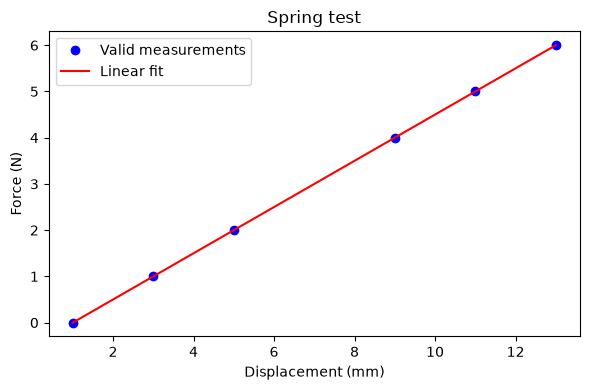

In [4]:
# DO NOT CHANGE CODE BELOW THIS ---------------------------------
use_plot_fallback = False

if use_plot_fallback:
    plot_x = np.array([0., 1., 2., 4., 5., 6.])
    plot_y = np.array([1., 3., 5., 9., 11., 13.])
    plot_fit = {"slope": 2.0, "intercept": 1.0}
else:
    plot_x, plot_y = valid_x, valid_y
    plot_fit = fit_result

line_x = np.linspace(np.min(plot_x), np.max(plot_x), 50)
line_y = plot_fit["slope"] * line_x + plot_fit["intercept"]
fig, ax = plt.subplots(figsize=(6, 4))
# DO NOT CHANGE CODE ABOVE THIS -----------------------------------

# TODO: repair these two calls and add labels, a title, and a legend.
ax.plot(plot_x, plot_y, 'bo', label='Valid measurements')
ax.plot(line_x, line_y, 'r-', label='Linear fit')
ax.set_title("Spring test")
ax.set_xlabel('Displacement (mm)')
ax.set_ylabel('Force (N)')
ax.legend()
# DO NOT CHANGE CODE BELOW THIS -----------------------------------
fig.tight_layout()
plt.show()


## Task 4 — Repair a prediction and explain it (3 points)

The function below uses slope and intercept in the wrong places. Repair it to evaluate **y = slope × x + intercept**, using its arguments.

Calculate `predicted_force` at a displacement of `2.5 mm` from your `fit_result`. If Task 2 is unfinished, set `use_prediction_fallback = True` to use the supplied correct fit for this task only.

In [5]:
def predict_y(x, fit):
    # TODO: repair the expression.
    return fit["slope"] * x + fit["intercept"]

# DO NOT CHANGE CODE BELOW THIS -----------------------------------
use_prediction_fallback = False
prediction_fit = {"slope": 2.0, "intercept": 1.0} if use_prediction_fallback else fit_result
predicted_force = predict_y(2.5, prediction_fit)
print("Predicted force at 2.5 mm:", predicted_force, "N")


Predicted force at 2.5 mm: 0.75 N


**Task 4 response:** State your predicted force. Is this interpolation or extrapolation? Explain using the displacement range of the valid measurements.

[The predicted force is 0.75 N which is interpolation.]

## Submission

Restart the kernel, run all cells, save the notebook with its plot and outputs, and upload the `.ipynb` file before the timer ends. Leave attempted code in place for partial credit.